# Анализ маркетинговых данных банка
В этом блокноте представлен анализ набора данных `bank-additional-full.csv`, который включает данные, относящиеся к маркетинговым кампаниям банка. Главная цель — понять поведение клиентов и предсказать, оформит ли клиент срочный депозит.

Задача этого проекта - проанализировать данные о клиентах и ​​кампаниях из маркетингового набора данных банка, чтобы выявить факторы, влияющие на оформление срочных депозитов. Анализ призван предоставить бизнес-аналитику и рекомендации, которые помогут банку улучшить свою маркетинговую стратегию и более эффективно ориентироваться на нужных клиентов.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


# Загрузка датасета
df = pd.read_csv(r"bank-additional\bank-additional-full2.csv", index_col=False)

# Отображение первых нескольких строк
df.head()


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [16]:
df.shape

(41188, 21)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [ ]:
# Проверка на отсутствующие числа и типы данных
df.isnull().sum()


age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(12)

# Проверка качества данных
- В наборе данных не обнаружено пропущенных значений
- Дублирующиеся записи не выявлены.
- Набор данных содержит:
    - 11 категориальных столбцов
    - 10 числовых столбцов

Это значит, что набор данных чист и пригоден для анализа.

In [ ]:
# Статистика
df.describe()


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


# Анализ целевой переменной

In [ ]:
# Целевая переменная
df['y'].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [ ]:
print(df['y'].value_counts(normalize=True) * 100)

# сильно несбалансированные данные (88.73% no и 11.26% yes)


y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


# Аналитические данные
- Данные сильно несбалансированы, 88,73% ответов «нет» и 11,26% ответов «да».
- Из-за сильного дисбаланса модель машинного обучения будет предвзятой, и банк упустит потенциальных клиентов, которые могли бы подписаться на услугу (да).



In [23]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [ ]:
# Переименовываем y
df = df.rename(columns={'y':'Subscribe'})
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,Subscribe
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
# Меняем местами столбцы и озаглавливаем слова
df = df.rename(columns=lambda x: x.replace('.', '_').capitalize())

In [26]:
df.head()

,Age,Job,Marital,Education,Default,Housing,Loan,Contact,Month,Day_of_week,...,Campaign,Pdays,Previous,Poutcome,Emp_var_rate,Cons_price_idx,Cons_conf_idx,Euribor3m,Nr_employed,Subscribe
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
# числовые столбцы
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
print("Numerical Columns:")
print(list(numerical_cols))

Numerical Columns:
['Age', 'Duration', 'Campaign', 'Pdays', 'Previous', 'Emp_var_rate', 'Cons_price_idx', 'Cons_conf_idx', 'Euribor3m', 'Nr_employed']


In [ ]:
# категориальные столбцы
categorical_cols = df.select_dtypes(include=['object']).columns
print("Categorical Columns:")
print(list(categorical_cols))

Categorical Columns:
['Job', 'Marital', 'Education', 'Default', 'Housing', 'Loan', 'Contact', 'Month', 'Day_of_week', 'Poutcome', 'Subscribe']


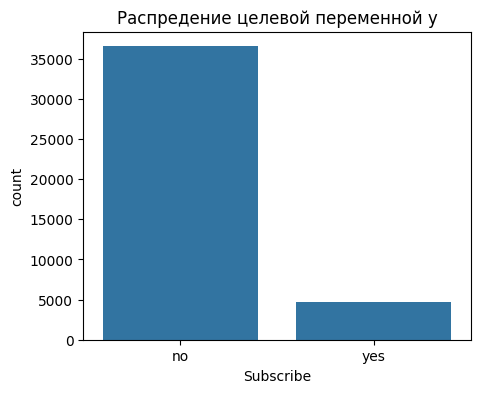

In [ ]:
# Одномерный анализ
plt.figure(figsize=(5,4))
sns.countplot(x = 'Subscribe', data= df)
plt.title("Распредение целевой переменной y")
plt.show()

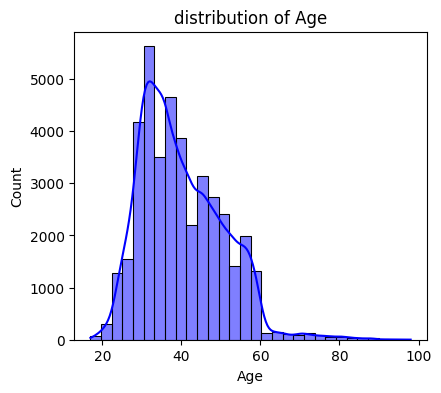

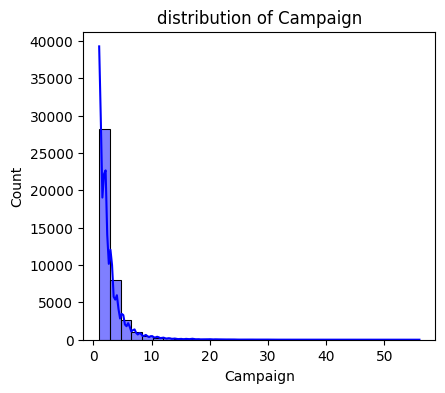

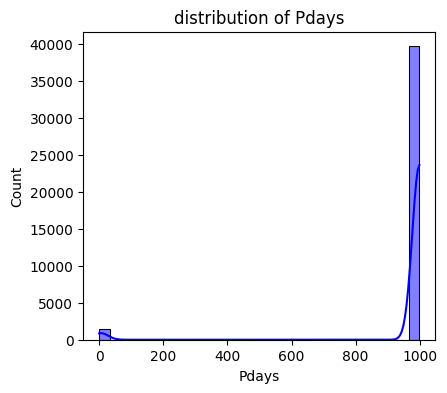

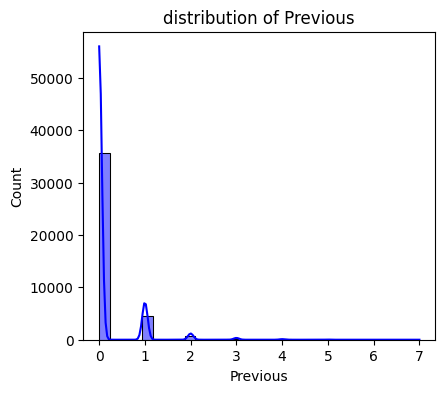

In [ ]:
# одномерный анализ числовых столбцов
num_cols = ['Age', 'Campaign', 'Pdays', 'Previous']

for col in num_cols:
    plt.figure(figsize=(10,4))
        # hisplot для проверки распредения данных
    plt.subplot(1,2,1)
    sns.histplot(df[col],bins=30, kde=True,color = "blue")  #bins = 30
    plt.title(f"distribution of {col}")

    # Диаграмма размаха для проверки на наличие выбросов
    # plt.subplot(1,2,2)
    # sns.boxplot(x=df[col], color = "lightblue")
    # plt.title(f"outlier in {col} ")
    # plt.tight_layout()
    plt.show()

    

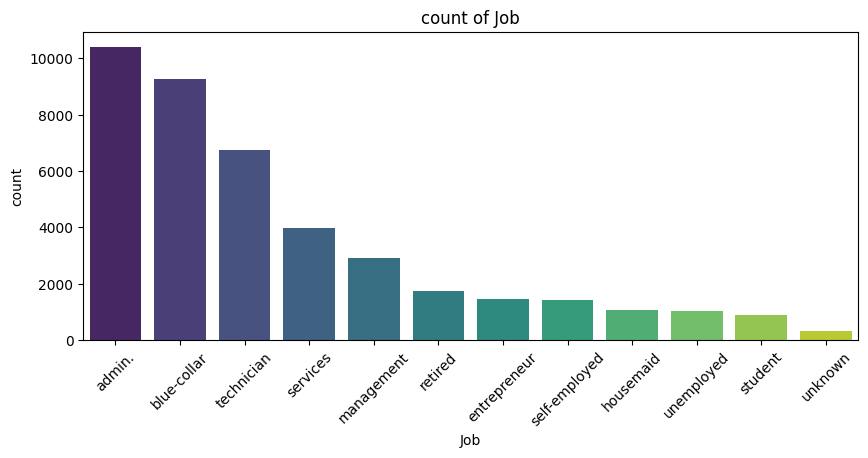

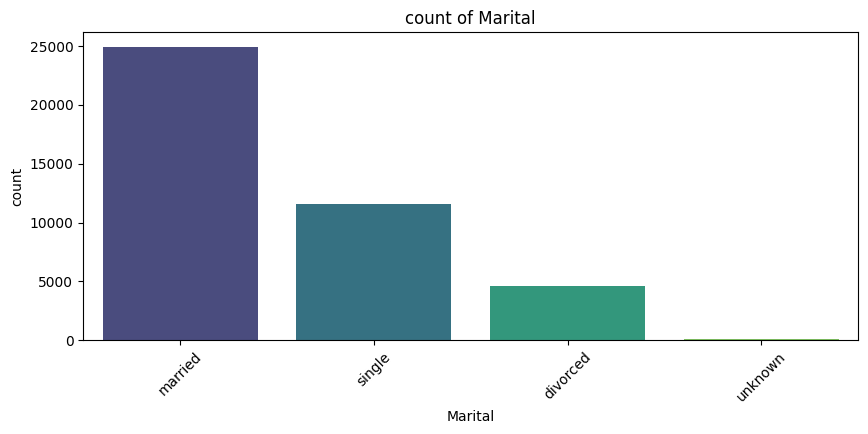

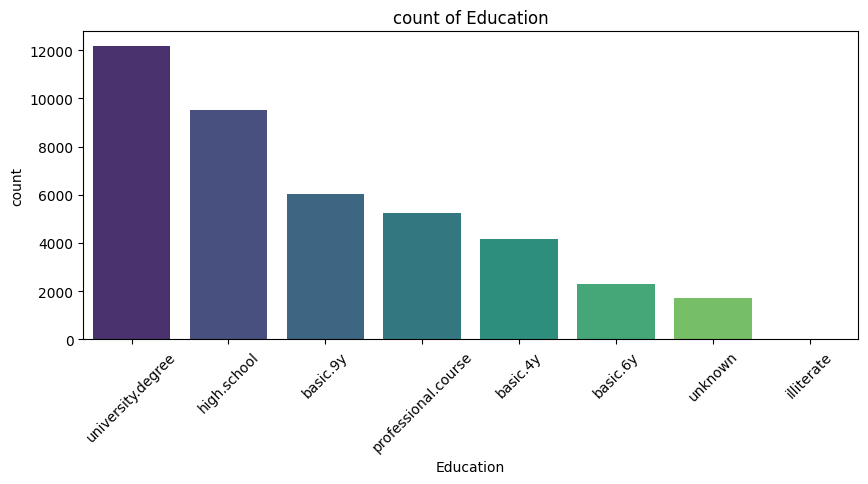

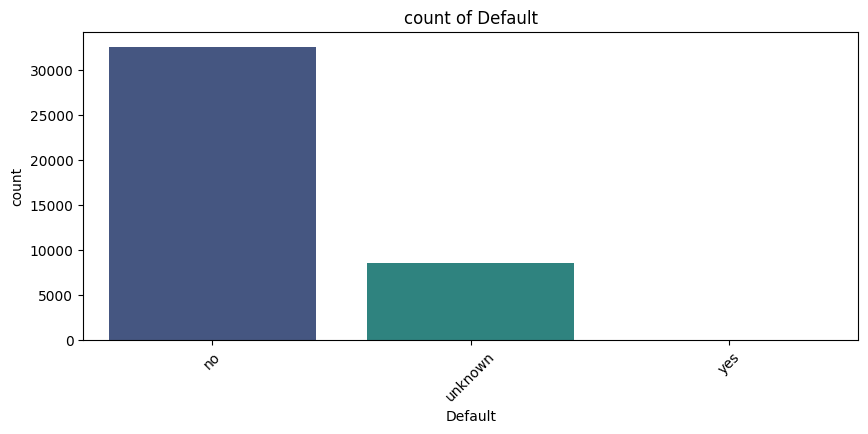

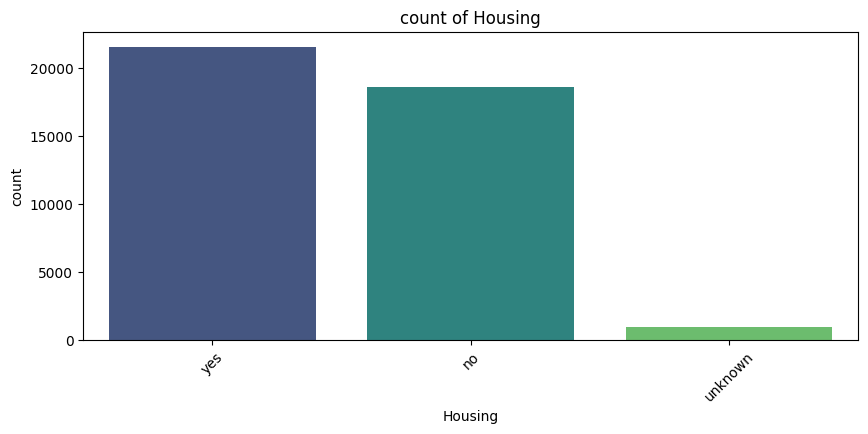

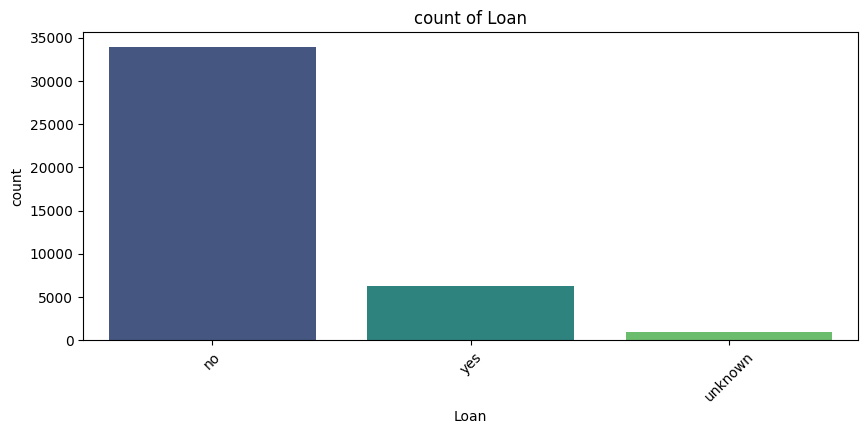

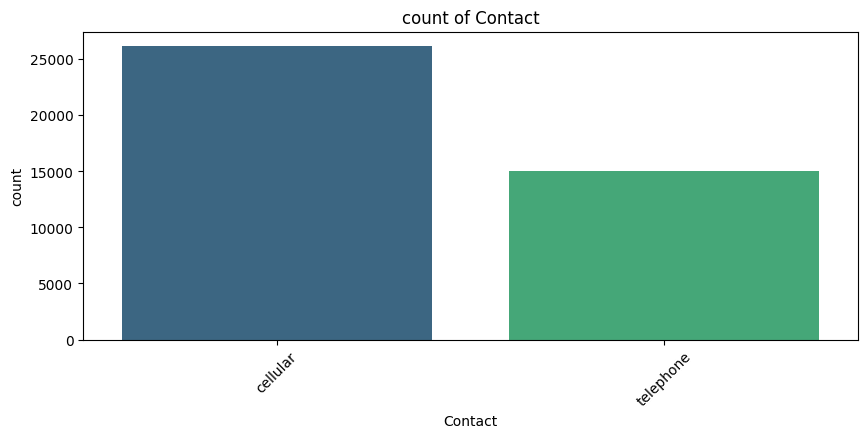

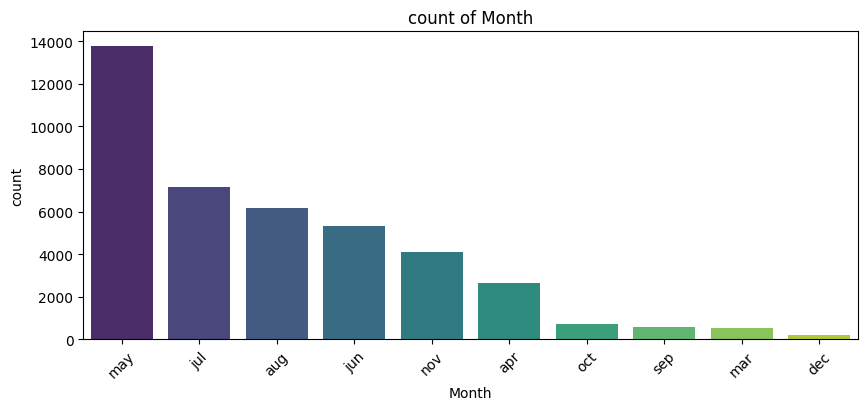

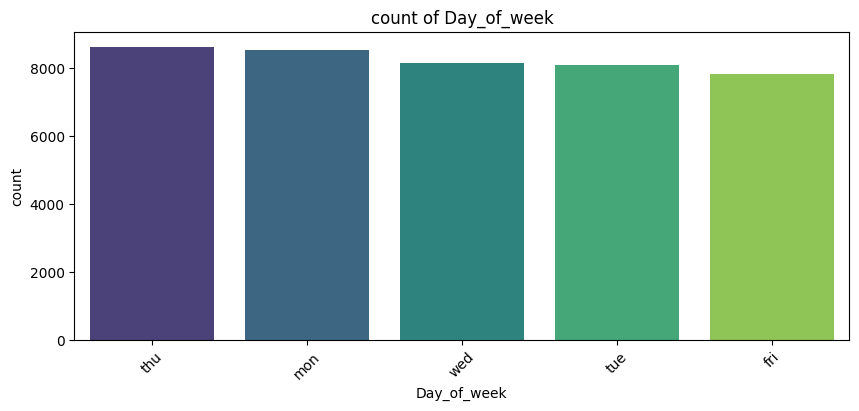

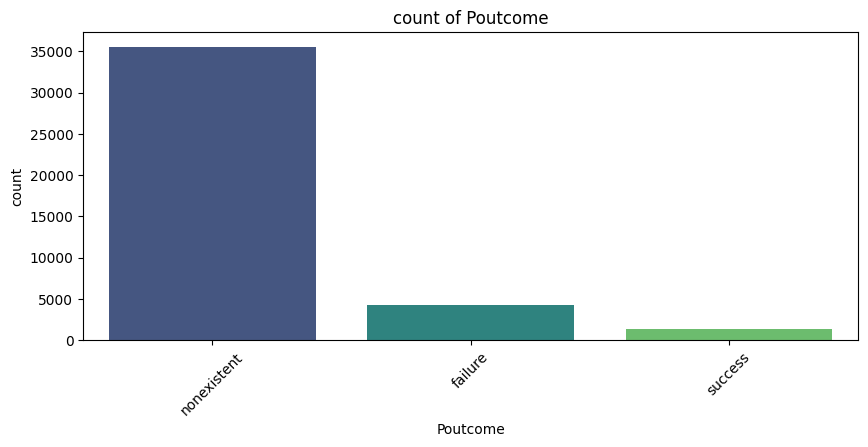

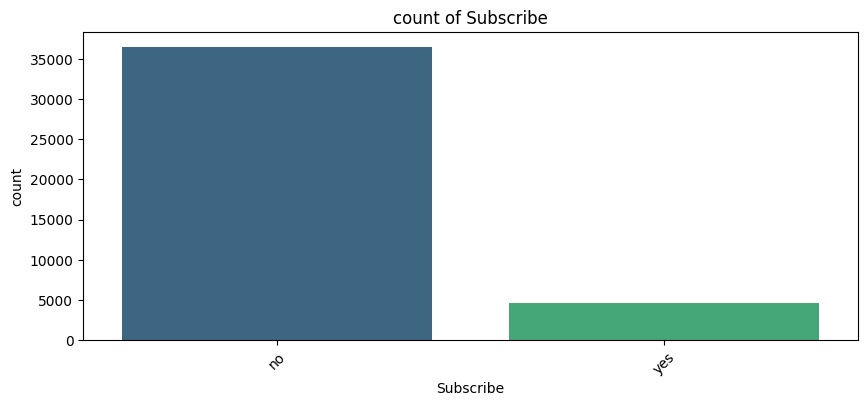

In [ ]:
# одномерный анализ по категориальным столбцам
cat_cols = ['Job', 'Marital', 'Education', 'Default', 'Housing', 'Loan', 'Contact', 'Month', 'Day_of_week', 'Poutcome', 'Subscribe']
for col in cat_cols:
    plt.figure(figsize=(10,4))

    sns.countplot(data = df, x = df[col], palette ='viridis', order = df[col].value_counts().index)
    plt.title(f"count of {col}")
    plt.xticks(rotation = 45)
    plt.show()

In [27]:
# plt.figure(figsize=(8,5))
# sns.boxplot(x='Y', y='Age', data=df)
# plt.title('Age vs Subscription')
# plt.show()

In [28]:
# plt.figure(figsize=(8,5))
# sns.boxplot(x='Y', y='Age', data=df)
# plt.title('Age vs Subscription')
# plt.show()

In [29]:
# plt.figure(figsize=(12,5))
# sns.countplot(y='Education', hue='Y', data=df)
# plt.title('Education vs Subscription')
# plt.show()

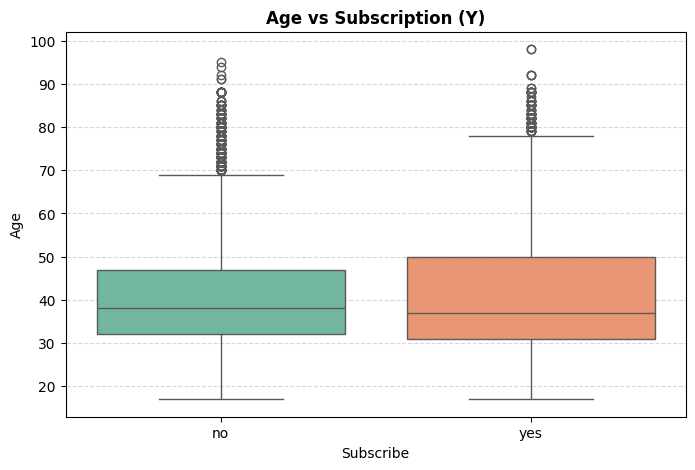

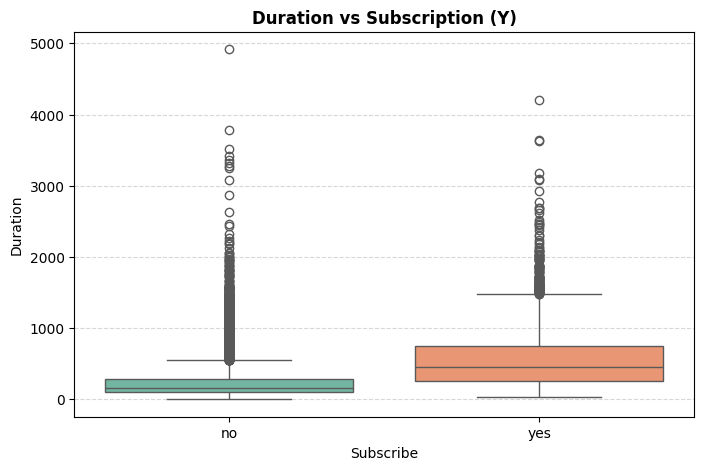

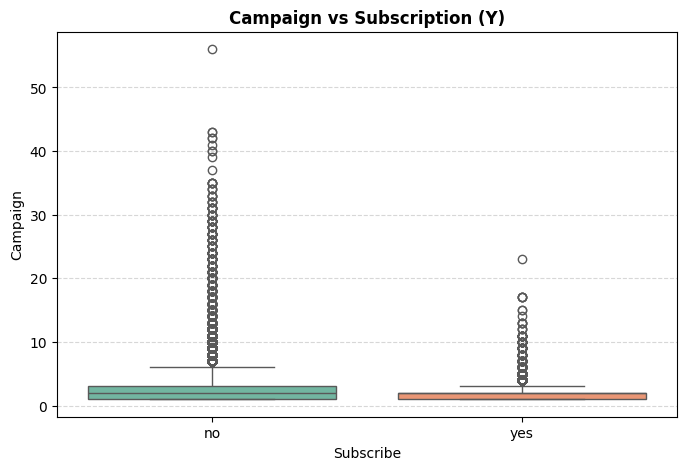

In [ ]:
# Двумерный анализ для числовых столбцов

num_cols = ['Age', 'Duration', 'Campaign']

for col in num_cols:
    plt.figure(figsize=(8, 5))
    # 'Y' on the x-axis splits the boxplot into "yes" vs "no" groups
    sns.boxplot(x= 'Subscribe', y=col, data=df, palette='Set2')
    plt.title(f'{col} vs Subscription (Y)', fontsize=12, fontweight='bold')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()


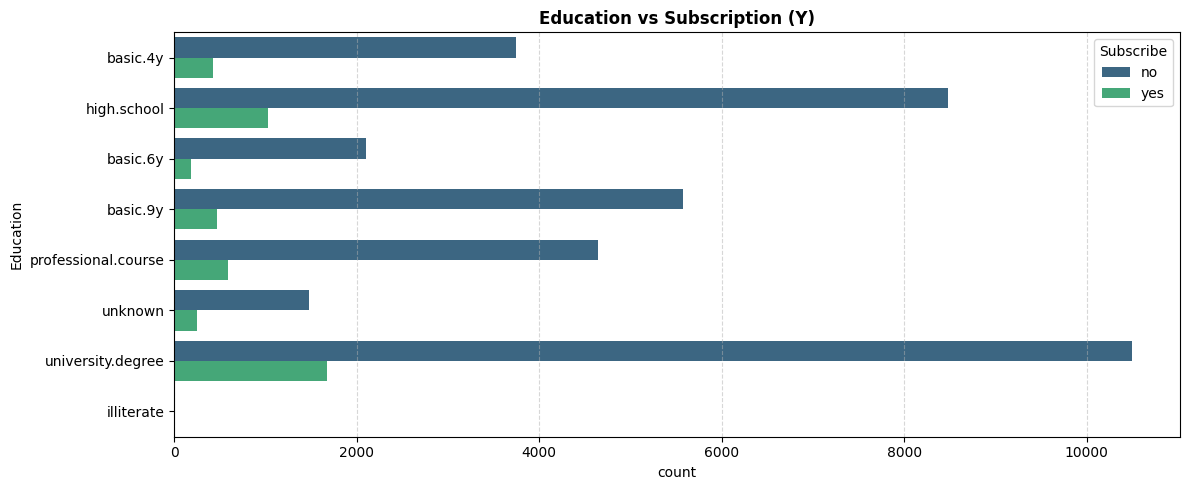

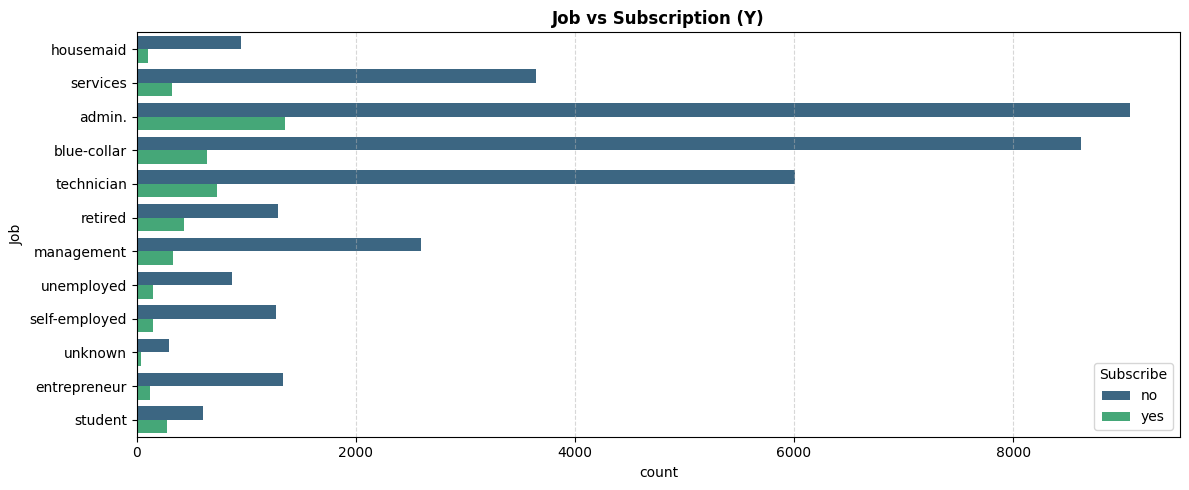

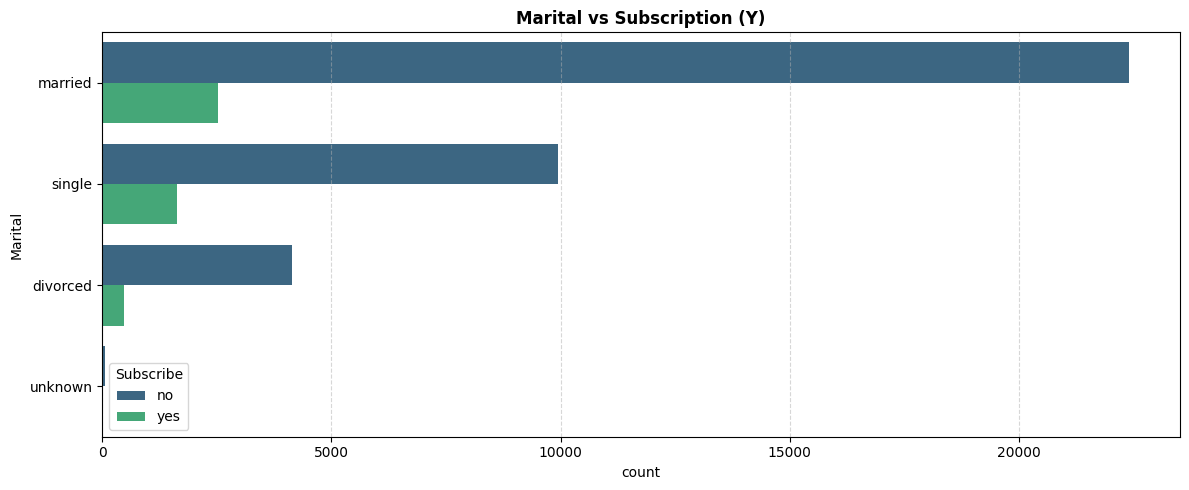

In [ ]:
# Двумерный анализ для категориальных столбцов (не считая'Y')

cat_cols = ['Education', 'Job', 'Marital']

for col in cat_cols:
    plt.figure(figsize=(12, 5))
    sns.countplot(y=col, hue= 'Subscribe', data=df, palette='viridis') #order=df[col].value_counts().index)
    plt.title(f'{col} vs Subscription (Y)', fontsize=12, fontweight='bold')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


# Анализ видов работы

In [ ]:
# Оценка подписок

job_sub = pd.crosstab(df['Job'], df['Subscribe'], normalize='index') * 100
job_sub.sort_values(by='yes', ascending=False)

Subscribe,no,yes
Job,,
student,68.571429,31.428571
retired,74.767442,25.232558
unemployed,85.798817,14.201183
admin.,87.027442,12.972558
management,88.782490,11.217510
unknown,88.787879,11.212121
technician,89.173958,10.826042
self-employed,89.514426,10.485574
housemaid,90.000000,10.000000


# Выводы
Наиболее распространенные категории вакансий:
- Admin
- Blue_collar
- Technician

  Однако, после анализа процента подписчиков:
- Студенты (Student) показали самый высокий процент подписчиков (~31%)
- Пенсионеры (Retired) второй по величине процент подписчиков (~25%)

    Вывод:
    
    Больше всего людей работали админами, но у студентов и пенсионеров шанс согласиться был больше всего, что делает их целевой группой.

# Анализ образования

In [ ]:
edu_sub = pd.crosstab(df['Education'], df['Subscribe'], normalize='index') * 100
edu_sub.sort_values(by='yes', ascending=False)

Subscribe,no,yes
Education,,
illiterate,77.777778,22.222222
unknown,85.499711,14.500289
university.degree,86.275477,13.724523
professional.course,88.651535,11.348465
high.school,89.164477,10.835523
basic.4y,89.750958,10.249042
basic.6y,91.797557,8.202443
basic.9y,92.175352,7.824648


In [34]:
df['Education'].value_counts()

Education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64



Большинство клиентов имеют:
- Высшее образование
- Среднее образование

Клиенты с высшим и средним образованием представляют собой более надежные сегменты клиентов благодаря большому размеру выборки.

Примечание: Хотя категория неграмотных имеет самый высокий процент подписчиков, размер выборки слишком мал (всего 18 клиентов), что делает ее ненадежной для принятия бизнес-решений. Для практического таргетинга клиенты с высшим и средним образованием являются более надежными благодаря большей клиентской базе.

# Анализ кредитов и финансового состояния

In [ ]:
# Ипотека и подписка

housing_sub = pd.crosstab(df['Housing'], df['Subscribe'], normalize='index') *100
housing_sub.sort_values(by='yes', ascending= False)

# У клиентов без ипотечных кредитов наблюдается чуть более высокий уровень подписки по сравнению с клиентами у которых есть ипотечные кредиты.

Subscribe,no,yes
Housing,,
yes,88.380608,11.619392
no,89.120395,10.879605
unknown,89.191919,10.808081


In [ ]:
# Личный кредит

personal_sub = pd.crosstab(df['Loan'], df['Subscribe'], normalize='index') * 100
personal_sub.sort_values(by='yes', ascending=False)

# Клиенты, имеющие потребительские кредиты, реже подписываются на депозит, веротяно, потому что у них уже есть финансовые обязательства.

Subscribe,no,yes
Loan,,
no,88.659794,11.340206
yes,89.068502,10.931498
unknown,89.191919,10.808081


In [ ]:
# Просрочка кредита и подписка

credit_sub = pd.crosstab(df['Default'], df['Subscribe'], normalize='index') * 100
credit_sub.sort_values(by='yes', ascending=False)

# У клиентов с историей просрочек по кредитам практически нет подписок, в то время как у клиентов без просрочек уровень подписок выше (~12%). Это говорит о том, что финансово стабильные клиенты с большей вероятностью подпишутся на услугу.


Subscribe,no,yes
Default,,
no,87.121026,12.878974
unknown,94.847040,5.152960
yes,100.000000,0.000000


Ипотечный кредит
- Клиенты без ипотечного кредита демонстрировали несколько более высокую активность в оформлении депозитов, чем клиенты с ипотечным кредитом.

Потребительский кредит
- Клиенты с потребительскими кредитами чаще оформляли срочные депозиты.

Аналитические данные

- Наличие финансовых обязательств может снизить готовность клиентов инвестировать в дополнительные банковские продукты.

Кредитная неплатежность
- Клиенты с историей неплатежей практически не оформляли депозиты, в то время как у клиентов без неплатежей уровень оформления депозитов составлял около 12%.

#### Вывод

- Финансово стабильные клиенты чаще оформляют депозиты.

# Способ связи

In [ ]:
# способ связи и подписка

contact_sub = pd.crosstab(df['Contact'], df['Subscribe'], normalize='index') * 100
contact_sub.sort_values(by='yes', ascending=False)

Subscribe,no,yes
Contact,,
cellular,85.262393,14.737607
telephone,94.768679,5.231321


Способ связи по мобильному телефону показал лучшие результаты, чем телефонный.

Выводы:

Клиенты, с которыми связались по мобильному телефону, продемонстрировали более высокий рейтинг подписки.

# Анализ по месяцам

In [ ]:
# месяц и подписка
month_sub = pd.crosstab(df['Month'], df['Subscribe'], normalize='index') * 100
month_sub.sort_values(by='yes', ascending=False)

Subscribe,no,yes
Month,,
mar,49.450549,50.549451
dec,51.098901,48.901099
sep,55.087719,44.912281
oct,56.128134,43.871866
apr,79.521277,20.478723
aug,89.397863,10.602137
jun,89.488530,10.511470
nov,89.856133,10.143867
jul,90.953443,9.046557


- В марте был зафиксирован самый высокий уровень подписки (~50%)
- В декабре был второй по величине уровень подписки (~45%)

Примечание:

Эти результаты следует проверить на выборке большего размера, прежде чем принимать обоснованные бизнес-решения.



# Результат предыдущей маркетинговой кампании (poutcome)

In [ ]:
# Результат предыдущей кампании 
poutcome_sub = pd.crosstab(df['Poutcome'], df['Subscribe'], normalize='index') * 100
print(poutcome_sub)

Subscribe           no        yes
Poutcome                         
failure      85.771402  14.228598
nonexistent  91.167787   8.832213
success      34.887109  65.112891


In [41]:
df['Poutcome'].value_counts()

Poutcome
nonexistent    35563
failure         4252
success         1373
Name: count, dtype: int64



- Клиенты с успешными результатами предыдущих кампаний показали самый высокий уровень подписки (~65%).
- Клиенты с неудачными предыдущими кампаниями показали значительно более низкий уровень подписки.

Вывод:

- Клиенты, ранее успешно проводившие кампании, с высокой вероятностью подпишутся снова, и им следует отдавать приоритет.

# Анализ корреляции

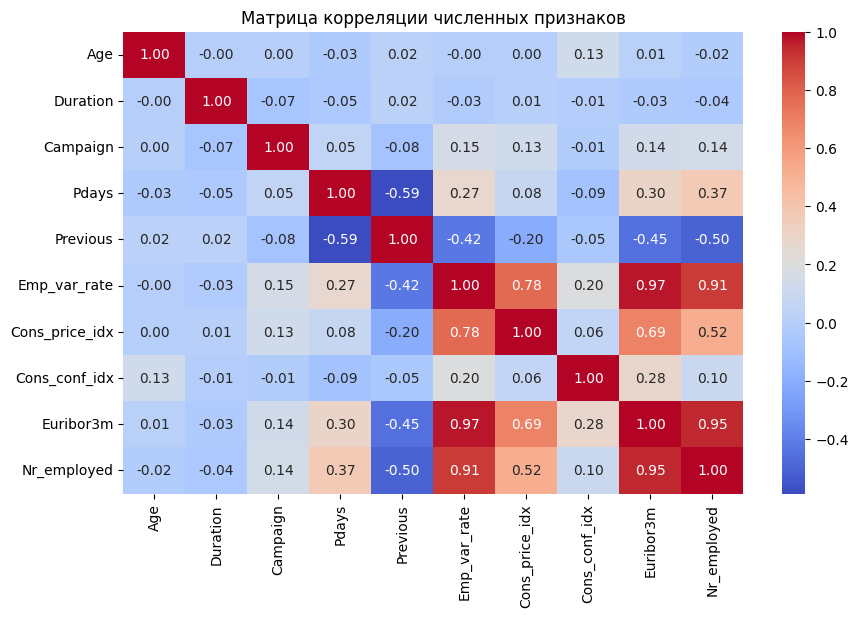

In [ ]:
# Матрица корреляции численных значений

plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Матрица корреляции численных признаков')
plt.show()



# Анализ данных
- Тепловая карта показывает сильную положительную корреляцию между экономическими показателями, такими как emp_var_rate, euribor3m и nr_employed, что указывает на возможную мультиколлинеарность. Кроме того, pdays и previous демонстрируют умеренную отрицательную корреляцию (-0,59). Большинство других числовых переменных показывают слабую корреляцию, что предполагает их независимый вклад в набор данных.

# Рекомендации для бизнеса
На основе проведенного анализа предлагаются следующие рекомендации:
- Приоритет отдавать маркетинговым кампаниям в мобильной связи по сравнению с телефонной коммуникацией, поскольку они обеспечивают более высокую реакцию клиентов.
- Ориентироваться на студентов и пенсионеров, так как у них выше уровень подписки.
- Сосредоточиться на финансово стабильных клиентах, особенно на тех, у кого нет потребительских кредитов или истории просрочек по кредитам.
- Вернуть клиентов с успешными результатами предыдущих кампаний, поскольку они с большей вероятностью подпишутся снова.
- Стратегически планировать кампании в наиболее успешные месяцы, такие как март и декабрь, после подтверждения объема клиентов.
- Сосредоточить маркетинговые усилия на клиентах с высшим и средним образованием, поскольку они представляют собой более крупные и надежные группы клиентов.



## Заключение 

Анализ выявил несколько важных факторов, влияющих на поведение клиентов при оформлении подписки.

- Демографические данные клиентов, их финансовое положение, способы связи и результаты предыдущих кампаний играют важную роль в определении успеха подписки.
- Результаты показывают, что банк может повысить эффективность маркетинга, ориентируясь на группы клиентов с высокой конверсией, оптимизируя методы коммуникации и используя исторические данные об успехе кампаний для планирования будущих кампаний.
